# Paper Example 5: Multi-Tracer Analysis (Tritium, Helium-3, SF6)

This notebook walks through Example 5 of the PyTracerLab paper. A single groundwater
sample (17 August 2004) with three tracers is available: tritium ($^3$H),
tritiogenic helium-3 ($^3$He$_\mathrm{trit}$, the decay product of tritium) and
SF$_6$. Data and model follow Example 1 of TracerLPM (Jurgens et al., 2012), using the
data as distributed with TracerLPM; the $^3$He$_\mathrm{trit}$ and SF$_6$ values are
processed values as reported there.

1. **Tracer-tracer plots:** the concentrations at the sampling date are simulated for
   mean travel times of 1-500 yr with several model types, and the dispersion model
   is compared with TracerLPM.
2. **Parameter inference:** the mean travel time and the dispersion parameter of the
   dispersion model are inferred from all three tracers with DREAM.

The script [`example_5.py`](https://github.com/iGW-TU-Dresden/PyTracerLab/blob/main/docs/examples/paper/example_5.py) produces the figures and numbers of
the paper.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

import PyTracerLab as lab

## 1. Data

The input file has semi-annual values of tritium (TU) and SF$_6$ (pptv) from 1900 to
2020. PyTracerLab needs one input column per simulated tracer, so the column
`3He(trit)` repeats the tritium input: tritiogenic helium-3 is produced by the decay
of tritium. The observation file contains the sample and, in the columns ending in
`_sd`, the measurement uncertainty (one standard deviation) of each tracer.

In [2]:
inp = lab.read_series("example_5_input.csv")
obs = lab.read_series("example_5_observations.csv", align_to=inp)
# the sample is assigned to the semi-annual time step that contains its date
step = int(np.where(np.isfinite(obs.values).all(axis=1))[0][0])
o, sd = obs.values[step], obs.uncertainty[step]
print("Tracers:", inp.tracers, "| sample at", inp.times[step])
for name, v, s in zip(obs.tracers, o, sd):
    print(f"{name:10s} {v:6.2f} ± {s:.2f}")

tlpm_raw = np.loadtxt("example_5_tracerlpm.csv", delimiter=",", skiprows=1)
tlpm_mtt, tlpm = tlpm_raw[:, 0], tlpm_raw[:, 1:]  # TracerLPM, dispersion model with DP = 0.8

Tracers: ['3H', '3He(trit)', 'SF6'] | sample at 2004-07-01 00:00:00
3H           4.57 ± 1.00
3He(trit)   32.70 ± 1.00
SF6          0.75 ± 0.50


## 2. Model with Three Tracers

Each tracer has its own decay constant: tritium decays, SF$_6$ does not
(`lambda_=0`). For helium-3, `production=True` tells the model that the tracer is
produced by the decay of the input (tritium) instead of decaying itself. The
steady-state input (before 1900) is 3 TU for tritium and 0 for SF$_6$.

In [3]:
lam = lab.decay_constant("Tritium")


def make_model(target=None):
    return lab.Model(
        dt=0.5,
        lambda_=[lam, lam, 0.0],  # 3H, 3He(trit), SF6
        input_series=inp.values,
        target_series=target,
        production=[False, True, False],
        steady_state_input=[3.0, 3.0, 0.0],
        time_steps=inp.times,
    )


def sweep(unit, mtt):
    """Concentrations of all tracers at the sampling date for each mean travel time."""
    m = make_model()
    m.add_unit(unit, fraction=1.0, prefix="u")
    out = np.empty((len(mtt), 3))
    for j, tm in enumerate(mtt):
        m.set_param("u.mtt", tm)
        out[j] = m.simulate()[step]
    return out

## 3. Tracer-Tracer Plots: Model Comparison

Five model types with fixed shape parameters are simulated for mean travel times of
1-500 yr. The markers indicate mean travel times of 10, 30 and 100 yr.

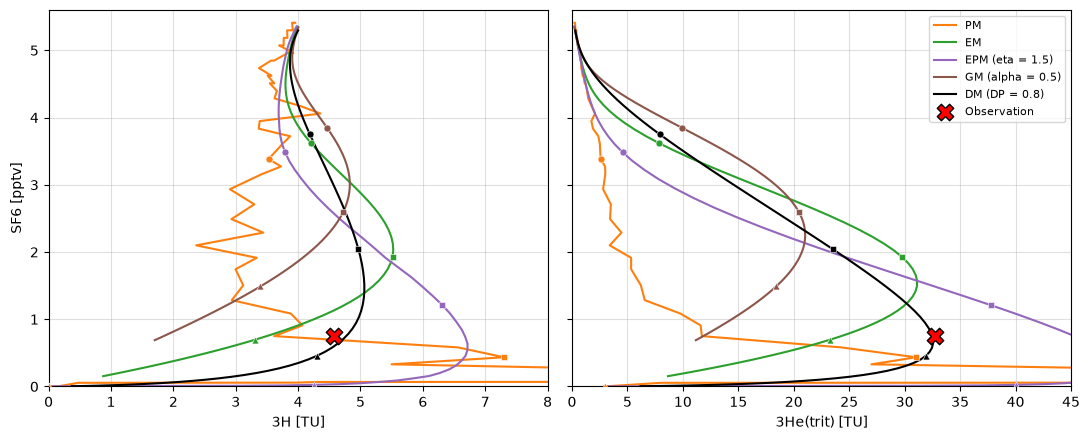

In [4]:
MTT = np.geomspace(1.0, 500.0, 91)
MODELS = [
    ("PM", lambda: lab.PMUnit(mtt=1.0), "tab:orange"),
    ("EM", lambda: lab.EMUnit(mtt=1.0), "tab:green"),
    ("EPM (eta = 1.5)", lambda: lab.EPMUnit(mtt=1.0, eta=1.5), "tab:purple"),
    ("GM (alpha = 0.5)", lambda: lab.GMUnit(mtt=1.0, alpha=0.5), "tab:brown"),
    ("DM (DP = 0.8)", lambda: lab.DMUnit(mtt=1.0, DP=0.8), "k"),
]
MARKED = {10.0: "o", 30.0: "s", 100.0: "^"}
curves = [sweep(make(), MTT) for _, make, _ in MODELS]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, c1, xlim in ((axes[0], 0, (0, 8)), (axes[1], 1, (0, 45))):
    for (name, _, colour), r in zip(MODELS, curves):
        ax.plot(r[:, c1], r[:, 2], c=colour, lw=1.5, label=name)
        for tm, mk in MARKED.items():
            j = int(np.argmin(np.abs(MTT - tm)))
            ax.scatter(r[j, c1], r[j, 2], marker=mk, s=25, c=colour, edgecolor="w", lw=0.4, zorder=6)
    ax.scatter(o[c1], o[2], marker="X", s=140, c="r", edgecolor="k", zorder=20, label="Observation")
    ax.set(xlim=xlim, ylim=(0, 5.6), xlabel=f"{inp.tracers[c1]} [TU]")
    ax.grid(True, alpha=0.4)
axes[0].set_ylabel("SF6 [pptv]")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Which model types can explain all three observations at once? For each model, the
table gives the smallest value of the largest deviation from the observations (in
standard deviations) and the range of mean travel times for which all three
simulated concentrations are within one standard deviation of the observations.

In [5]:
fine = np.geomspace(1.0, 500.0, 2000)
print(f"{'model':18s} {'min of max |sim - obs| / sd':>28s} {'at mtt [yr]':>12s}   mtt within 1 sd [yr]")
for name, make, _ in MODELS:
    z = (np.abs(sweep(make(), fine) - o) / sd).max(axis=1)
    inside = fine[z <= 1.0]
    within = f"{inside.min():.1f}-{inside.max():.1f}" if inside.size else "none"
    print(f"{name:18s} {z.min():28.2f} {fine[z.argmin()]:12.1f}   {within}")

model               min of max |sim - obs| / sd  at mtt [yr]   mtt within 1 sd [yr]


PM                                         2.10         46.8   none


EM                                         1.57         40.2   none


EPM (eta = 1.5)                            1.44         25.8   none


GM (alpha = 0.5)                          11.67         41.2   none


DM (DP = 0.8)                              0.14         79.6   61.5-105.7


## 4. Dispersion Model Compared with TracerLPM

For the dispersion model (DP = 0.8), the PyTracerLab curves (coloured by the mean
travel time) are compared with TracerLPM (black dotted line).

Max |PyTracerLab - TracerLPM| for mean travel times of 1-500 yr: {'3H': 0.057, '3He(trit)': 0.065, 'SF6': 0.034}


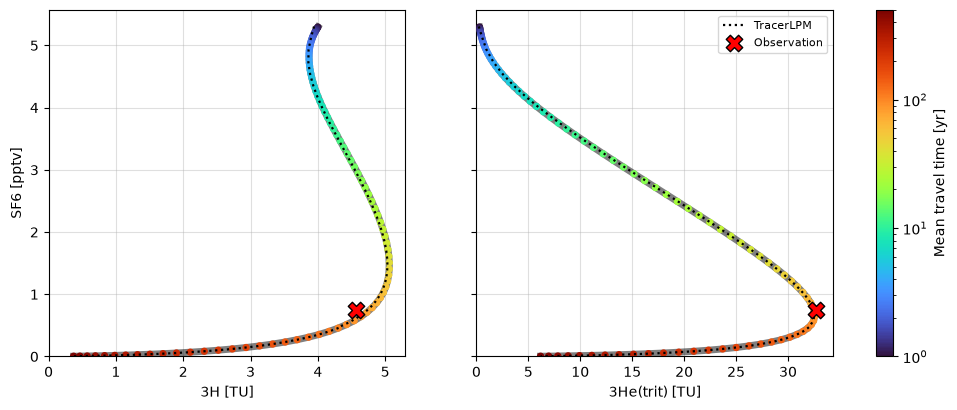

In [6]:
dm = curves[-1]
diff = sweep(lab.DMUnit(mtt=1.0, DP=0.8), tlpm_mtt) - tlpm
print("Max |PyTracerLab - TracerLPM| for mean travel times of 1-500 yr:",
      dict(zip(inp.tracers, np.round(np.abs(diff).max(axis=0), 3).tolist())))

norm = LogNorm(vmin=MTT[0], vmax=MTT[-1])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, c1 in ((axes[0], 0), (axes[1], 1)):
    ax.plot(dm[:, c1], dm[:, 2], c="k", lw=5, alpha=0.5, zorder=4)
    sc = ax.scatter(dm[:, c1], dm[:, 2], c=MTT, cmap="turbo", norm=norm, s=18, zorder=5)
    ax.plot(tlpm[:, c1], tlpm[:, 2], c="k", ls=":", lw=1.6, zorder=6, label="TracerLPM")
    ax.scatter(o[c1], o[2], marker="X", s=140, c="r", edgecolor="k", zorder=20, label="Observation")
    ax.set(xlim=(0, None), ylim=(0, None), xlabel=f"{inp.tracers[c1]} [TU]")
    ax.grid(True, alpha=0.4)
axes[0].set_ylabel("SF6 [pptv]")
axes[1].legend(fontsize=8)
fig.colorbar(sc, ax=axes, label="Mean travel time [yr]", fraction=0.03)
plt.show()

## 5. Parameter Inference with DREAM

The mean travel time and the dispersion parameter of the dispersion model are
inferred from all three tracers. The likelihood uses the uncertainties from the
`_sd` columns of the observation file (`sigma=obs.uncertainty`), so each tracer is
weighted with its own uncertainty.

In [7]:
m = make_model(target=obs.values)
m.add_unit(lab.DMUnit(mtt=10.0, DP=0.8), fraction=1.0, bounds=[(1.0, 1000.0), (0.01, 10.0)], prefix="dm")
dream = lab.Solver(m).dream_sample(n_samples=4000, burn_in=4000, n_chains=8, cr=[0.25, 0.5, 0.75, 1.0],
                                   sigma=obs.uncertainty, random_state=42)
print("R-hat:", {k: round(float(v), 3) for k, v in dream["gelman_rubin"].items()},
      "| outlier chains moved:", dream["n_outlier_resets"])
s, names = dream["samples"], dream["param_names"]
for i, k in enumerate(names):
    q = np.quantile(s[:, i], [0.01, 0.5, 0.99])
    print(f"{k:7s} MAP {dream['posterior_map'][k]:7.2f}   median {q[1]:7.2f}  [1-99 %: {q[0]:.2f}, {q[2]:.2f}]")

for k, v in dream["posterior_map"].items():
    m.set_param(k, v)
print("Simulated at the MAP:", dict(zip(inp.tracers, np.round(m.simulate()[step], 3).tolist())))

R-hat: {'dm.DP': 1.005, 'dm.mtt': 1.003} | outlier chains moved: 0
dm.DP   MAP    0.79   median    0.74  [1-99 %: 0.27, 1.02]
dm.mtt  MAP   77.98   median   88.38  [1-99 %: 37.52, 118.72]
Simulated at the MAP: {'3H': 4.728, '3He(trit)': 32.692, 'SF6': 0.694}


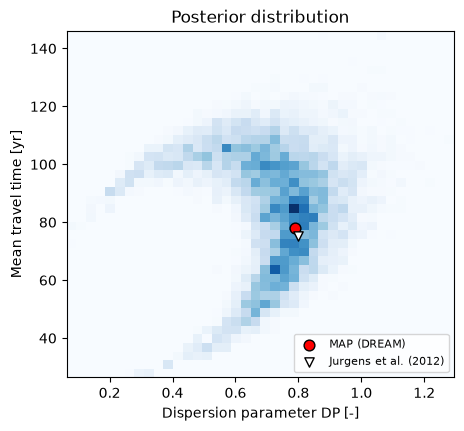

In [8]:
JURGENS = {"dm.DP": 0.8, "dm.mtt": 75.3}  # solution of Jurgens et al. (2012), Example 1
i_dp, i_mtt = names.index("dm.DP"), names.index("dm.mtt")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.hist2d(s[:, i_dp], s[:, i_mtt], bins=40, cmap="Blues")
ax.scatter(dream["posterior_map"]["dm.DP"], dream["posterior_map"]["dm.mtt"], s=60, c="r", edgecolor="k",
           zorder=10, label="MAP (DREAM)")
ax.scatter(JURGENS["dm.DP"], JURGENS["dm.mtt"], s=45, marker="v", c="w", edgecolor="k", zorder=11,
           label="Jurgens et al. (2012)")
ax.set(xlabel="Dispersion parameter DP [-]", ylabel="Mean travel time [yr]", title="Posterior distribution")
ax.legend(fontsize=8, loc="lower right")
plt.show()

With three tracers and two parameters, the posterior is still wide: for small
dispersion parameters, two branches with mean travel times of about 40 and 100 yr
explain the sample. Three tracers in a single sample constrain the model, but they
do not identify a unique travel time distribution.

## Further Reading

- Tutorial 3 shows tracer-tracer plots with synthetic data for two tracers.
- The user guide describes the `_sd` columns of the observation file and the
  measurement uncertainty options.